# Hard peak-cancellation CFR on the XCZU67DR

One digital 20 MHz carrier at 100 MS/s. The 16-bit source uses independent random subcarrier phases for each of 64 periodic symbols. Each has 4,096 samples. Repeating the symbol four times permits steady-state capture and integer-lag alignment. The calibrated low-amplitude constant-envelope sequence supplies the lag for every measurement. A fixed 249-tap Q14 pulse on a fourfold fractional-sample grid follows the carrier bandwidth. The driver zero-pads to 255 entries and writes four consecutive fractional-phase banks. The main result exercises the three PC stages. The final control enables WCFR as well.

In [1]:
import json, os, sys
from pathlib import Path
from IPython.display import display, Markdown, Image
example = Path(os.getenv('CFR_EXAMPLE', '../packages/pynq-dfe/examples/cfr')).resolve()
sys.path.insert(0, str(example))
from experiment import acquire, plot
output = Path(os.getenv('CFR_OUTPUT', 'cfr-results')).resolve()
output.mkdir(exist_ok=True)
frozen = (example / 'expectations.json').read_text()
(output / 'expectations.json').write_text(frozen)
print(frozen)

{
  "reference": {
    "ccdf_dB": [
      6.059003246447586,
      6.190080267030247,
      6.190091767515347
    ],
    "papr_dB": 6.190499554228643,
    "inband_power_dBFS": -14.91570305870258,
    "evm_pct": 6.172082232084023,
    "aclr_dB": [
      45.492836308770066,
      45.36005803898057
    ]
  },
  "evm_band_pct": [
    2.468832892833609,
    12.344164464168045
  ],
  "ccdf_tolerance_dB": 0.8,
  "tail_max_dB": 6.520599913279624,
  "min_aclr_dB": 35,
  "max_low_peak_error_lsb": 3,
  "min_input_papr_dB": 10
}



The PC and window thresholds are 12,000 counts, −8.73 dBFS or 6.021 dB above input mean power. The model subtracts a bandwidth-matched pulse at each local maximum in three passes. It approximates stage scheduling and the window postprocessor. Each CCDF point has a ±0.8 dB model tolerance. The 0.01% tail must also stay below 6.521 dB, each adjacent channel must be at least 35 dB below the occupied channel, and the low-level error must stay within three counts in complex magnitude. The ACLR limit is an experiment mask. EVM uses the in-band power of the aligned sample error without fitting gain or phase.

In [2]:
result = acquire(Path(os.environ['CFR_BITFILE']), output)
print('Lag (samples modulo 4096)', result['latency_mod_period'])
print('Before and after', json.dumps([result['before'], result['after']], indent=2))
table = ['| Test | Expected | Measured | Result |', '|---|---|---:|---|']
for row in result['rows']:
    status = 'PASS' if row['passed'] else 'FAIL'
    table.append(f"| {row['test']} | {row['expected']} | {row['measured']:.4f} | {status} |")
display(Markdown('\n'.join(table)))

Lag (samples modulo 4096) 373
Before and after [
  {
    "ccdf_dB": [
      6.6510579814204025,
      8.414083156808013,
      9.50426879190721
    ],
    "papr_dB": 10.76491903320254,
    "inband_power_dBFS": -14.74597377281739,
    "evm_pct": 0.0,
    "aclr_dB": [
      90.34964013784744,
      90.32590545503052
    ]
  },
  {
    "ccdf_dB": [
      5.9919996768336325,
      6.19755055586768,
      6.208312175209086
    ],
    "papr_dB": 6.232286625883582,
    "inband_power_dBFS": -14.922513624546475,
    "evm_pct": 6.289655403375321,
    "aclr_dB": [
      45.316595204233465,
      45.21231216091954
    ]
  }
]


| Test | Expected | Measured | Result |
|---|---|---:|---|
| input PAPR dB | >=10 | 10.7649 | PASS |
| CCDF 0.01 dB | 6.059 +/- 0.8 | 5.9920 | PASS |
| CCDF 0.001 dB | 6.190 +/- 0.8 | 6.1976 | PASS |
| CCDF 0.0001 dB | 6.190 +/- 0.8 | 6.2083 | PASS |
| tail cap dB | <= 6.521 | 6.2083 | PASS |
| in-band RMS EVM % | 2.469..12.344 | 6.2897 | PASS |
| lower ACLR dB | >=35 | 45.3166 | PASS |
| upper ACLR dB | >=35 | 45.2123 | PASS |
| low-level peak IQ error counts | <=3 | 0.0000 | PASS |

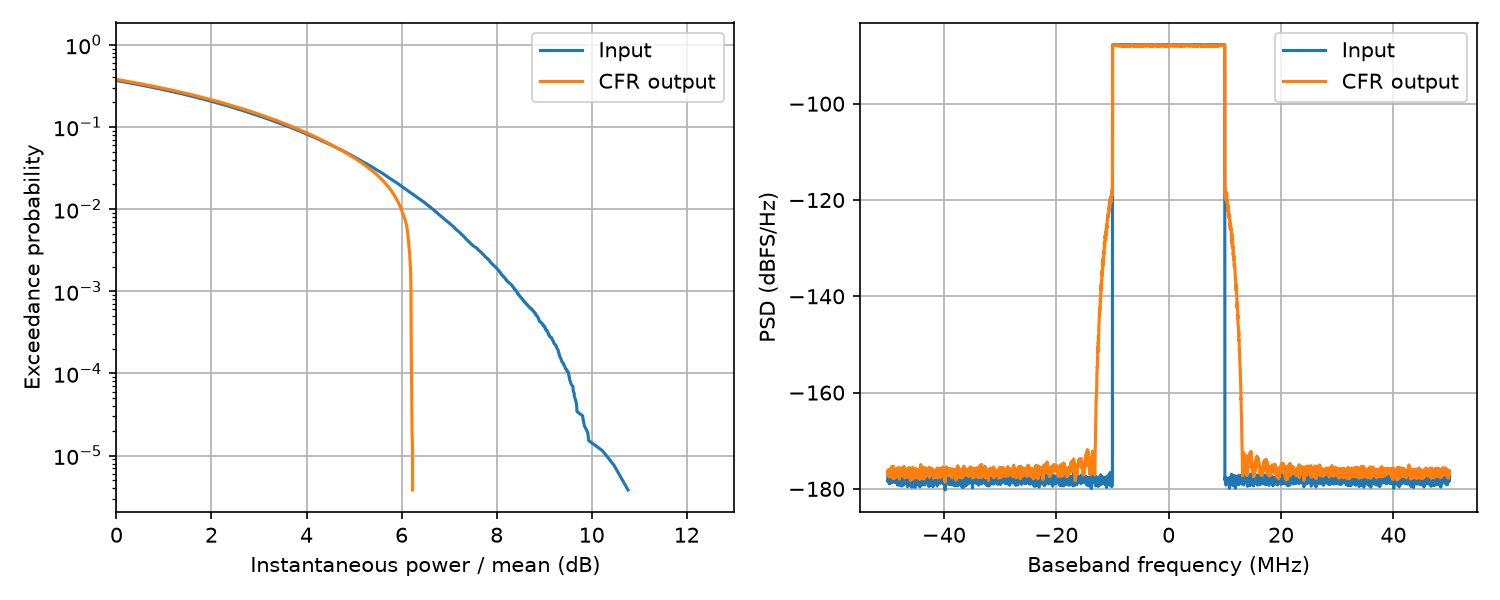

In [3]:
import matplotlib.pyplot as plt
fig = plot(output)
plt.close(fig)
display(Image(filename=str(output/'ccdf-spectrum.png')))

The left plot uses mean-normalized instantaneous power in dB on a linear horizontal axis and a logarithmic probability axis. The right plot shows the complex baseband spectrum at linear frequency spacing. ACLR integrates the two 20 MHz channels immediately beside the occupied band. The plots show the three PC stages.

### Window postprocessor control
Repeat the same stimulus and thresholds with WCFR enabled and inspect the low-level sample-order check. Each run stores its own raw captures.

In [4]:
window_result = acquire(Path(os.environ['CFR_BITFILE']), output/'window', window=True)
print('PC + WCFR', json.dumps(window_result, indent=2))

PC + WCFR {
  "before": {
    "ccdf_dB": [
      6.6510579814204025,
      8.414083156808013,
      9.50426879190721
    ],
    "papr_dB": 10.76491903320254,
    "inband_power_dBFS": -14.74597377281739,
    "evm_pct": 0.0,
    "aclr_dB": [
      90.34964013784744,
      90.32590545503052
    ]
  },
  "after": {
    "ccdf_dB": [
      5.992307334653769,
      6.193935047710619,
      6.205225911643836
    ],
    "papr_dB": 6.208272115441788,
    "inband_power_dBFS": -15.490107801809636,
    "evm_pct": 11.619965126182139,
    "aclr_dB": [
      46.792687444076215,
      46.68229124693619
    ]
  },
  "rows": [
    {
      "test": "input PAPR dB",
      "expected": ">=10",
      "measured": 10.76491903320254,
      "passed": true
    },
    {
      "test": "CCDF 0.01 dB",
      "expected": "6.059 +/- 0.8",
      "measured": 5.992307334653769,
      "passed": true
    },
    {
      "test": "CCDF 0.001 dB",
      "expected": "6.190 +/- 0.8",
      "measured": 6.193935047710619,
      "pass